# Détecteur et classifieur d'objets spatiaux

## Pipeline de classification binaire

Ce projet accompagne une mission de nettoyage de l'environnement spatial : son objectif est de distinguer rapidement un objet de type satellite d'un debris, puis de signaler les cas qui nécessitent une vérification humaine.

Le jeu Roboflow contient initialement 11 classes. Elles sont volontairement regroupées en deux sorties pour simplifier la mission : `satellite` rassemble les objets satellites connus, tandis que `debris` rassemble les objets à surveiller ou retirer. Nous ne cherchons pas à reconnaître le nom exact de chaque satellite : nous ne sommes pas spécialistes de ces modèles techniques, et cette identification précise n'est pas nécessaire pour décider qu'un objet doit faire l'objet d'une alerte.

Le notebook construit les ensembles TensorFlow, applique un fine-tuning de MobileNetV2, compense le déséquilibre des données, compare les taux d'apprentissage, choisit le seuil sur la validation et mesure ensuite les performances sur le test.


## Objectif du notebook

La sortie du modèle est une probabilité comprise entre 0 et 1 : proche de 0 pour un satellite, proche de 1 pour un débris. Le pipeline réalise successivement :

1. lecture des images JPEG et des annotations YOLO ;
2. regroupement des dix classes satellites en une seule classe `satellite` ;
3. création des datasets `train`, `valid` et `test` ;
4. transfert d'apprentissage avec MobileNetV2 pré-entraîné sur ImageNet ;
5. entraînement avec poids de classe pour éviter que les satellites dominent la perte ;
6. comparaison des taux d'apprentissage fixe, cosinus et réduction sur plateau ;
7. choix du seuil sur la validation puis mesure finale sur le test.

Le jeu de test n'est utilisé dans aucune décision d'hyperparamètre ou de seuil : il ne sert qu'à estimer la capacité de généralisation.

In [1]:
from pathlib import Path
import sys

# BLOQUE 1 - Imports, environnement et configuration globale
# Cette cellule charge TensorFlow, NumPy, Pandas, Matplotlib et YAML, puis fixe
# la taille 224x224, les lots de 16 et la liste binaire satellite/debris.
# Elle détecte également GPU/CPU afin de rendre les cellules exécutables sur les deux environnements.
import glob
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import yaml

from UTILS.logging_settings import setup_logging
import logging

_cwd = Path.cwd().resolve()
_candidates = [_cwd, _cwd.parent, _cwd / "src"]
PROJECT_ROOT = next((p for p in _candidates if (p / "data").is_dir()), _cwd)
PROJECT_ROOT = PROJECT_ROOT.resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)
logging.info("Répertoire projet utilisé : %s", PROJECT_ROOT)


# Development: colored console + timestamped file + cleaned/displayed traceback
setup_logging(level=logging.DEBUG, log_file="log_file", console=True, enable_traceback=True)

# Configuration globale
IMG_SIZE = 224
BATCH_SIZE = 16

# Choix du périphérique : GPU s'il est disponible, sinon CPU
GPU_DEVICES = tf.config.list_physical_devices("GPU")
if GPU_DEVICES:
    for gpu in GPU_DEVICES:
        try:
            # Alloue la mémoire GPU au besoin au lieu de tout réserver dès le départ
            tf.config.experimental.set_memory_growth(gpu, True)
        except RuntimeError:
            # GPU déjà initialisé (cellule réexécutée) : le réglage reste celui de la première exécution
            pass
    TRAINING_DEVICE = "/GPU:0"
    gpu_names = [tf.config.experimental.get_device_details(gpu).get("device_name", gpu.name) for gpu in GPU_DEVICES]
    logging.info(f"Entraînement sur GPU : {gpu_names}")
else:
    TRAINING_DEVICE = "/CPU:0"
    logging.warning("Aucun GPU détecté : entraînement sur CPU")



DATA_YAML_PATH = 'data/data.yaml'
with open(DATA_YAML_PATH, 'r', encoding='utf-8') as yaml_file:
    dataset_config = yaml.safe_load(yaml_file)

ORIGINAL_CLASS_NAMES = dataset_config['names']
CLASS_NAMES = ['satellite', 'debris']
NUM_CLASSES = len(CLASS_NAMES)

logging.info(f"TensorFlow version: {tf.__version__}")
logging.info(f"Classes originales : {ORIGINAL_CLASS_NAMES}")
logging.info(f"Classes du modèle : {CLASS_NAMES}")

I0000 00:00:1795596472.066478  305738 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795596472.092421  305738 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795596472.639328  305738 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 09:47:53 [INFO] : root : Entraînement sur GPU : ['NVIDIA GeForce RTX 5090']
W0000 00:00:179559

## 1. Préparation des données

### 1.1. Construction du DataFrame de classification

Chaque fichier `.jpg` est associé à son fichier `.txt` portant le même nom. Ce fichier contient au moins une annotation YOLO. Le code récupère son identifiant, transforme cet identifiant en classe binaire et conserve le chemin de l'image.

- `binary_class_id = 0` : tous les objets appartenant aux dix catégories de satellites ;
- `binary_class_id = 1` : classe `debris` ;
- `binary_class_name` : nom lisible utilisé pour les affichages et les rapports.

Cette étape permet de séparer clairement la préparation des données de la construction du modèle.

In [2]:
# BLOQUE 2 - Chargement des annotations et création des DataFrames
# Pour chaque image, le code lit son fichier YOLO, conserve son chemin et transforme
# l'identifiant de classe original en cible 0 (satellite) ou 1 (debris).
def create_dataset_dataframe(image_dir):
    """Lire les annotations YOLO et créer une cible de classification binaire."""
    image_paths = sorted(glob.glob(os.path.join(image_dir, '*.jpg')))
    records = []

    for img_path in image_paths:
        label_path = img_path.replace('images', 'labels').replace('.jpg', '.txt')
        if not os.path.exists(label_path):
            continue

        with open(label_path, 'r', encoding='utf-8') as label_file:
            line = label_file.readline().strip()
        if not line:
            continue

        cls_id = int(line.split()[0])
        original_class_name = (
            ORIGINAL_CLASS_NAMES[cls_id]
            if 0 <= cls_id < len(ORIGINAL_CLASS_NAMES)
            else 'unknown'
        )
        binary_class_id = int(original_class_name == 'debris')
        records.append({
            'image_path': img_path,
            'class_id': cls_id,
            'class_name': original_class_name,
            'binary_class_id': binary_class_id,
            'binary_class_name': CLASS_NAMES[binary_class_id],
        })

    return pd.DataFrame(records)

df_train = create_dataset_dataframe('data/train/images')
df_val = create_dataset_dataframe('data/valid/images')
df_test = create_dataset_dataframe('data/test/images')

logging.info(f"Train : {len(df_train)} images")
logging.info(f"Val   : {len(df_val)} images")
logging.info(f"Test  : {len(df_test)} images")
logging.info("Distribution binaire (Train) :")
logging.info(df_train['binary_class_name'].value_counts())
df_train.head()


2026-11-25 09:47:53 [INFO] : root : Train : 2105 images
2026-11-25 09:47:53 [INFO] : root : Val   : 239 images
2026-11-25 09:47:53 [INFO] : root : Test  : 123 images
2026-11-25 09:47:53 [INFO] : root : Distribution binaire (Train) :
2026-11-25 09:47:53 [INFO] : root : binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


,image_path,class_id,class_name,binary_class_id,binary_class_name
0,data/train/images/img000008_jpg.rf.2c95cb6fb03...,5,proba_2,0,satellite
1,data/train/images/img000008_jpg.rf.9f76dc15cc1...,5,proba_2,0,satellite
2,data/train/images/img000009_jpg.rf.1142d9cc183...,5,proba_2,0,satellite
3,data/train/images/img000009_jpg.rf.1c26d8ebd8e...,5,proba_2,0,satellite
4,data/train/images/img000009_jpg.rf.da7b45fe680...,5,proba_2,0,satellite


## 2. Exploration des données

### 2.1. Distribution binaire du jeu d'entraînement

Les compteurs permettent de mesurer directement le déséquilibre au lieu de le supposer. Dans les données analysées, l'entraînement contient 1919 satellites pour 186 debris. Cette proportion est importante pour interpréter l'accuracy, qui peut être trompeuse lorsqu'une classe est minoritaire.

In [3]:
# BLOQUE 3 - Mesure du déséquilibre
# Cette sortie vérifie que le nombre de satellites et de debris est bien enregistré
# avant tout entraînement et sert de preuve pour le choix des poids de classe.
logging.info("Distribution des classes binaires (Train) :")
logging.info(df_train['binary_class_name'].value_counts())

2026-11-25 09:47:53 [INFO] : root : Distribution des classes binaires (Train) :
2026-11-25 09:47:53 [INFO] : root : binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64


## 2.2. Gestion du déséquilibre

Nous avons choisi de conserver les 2105 images originales plutôt que de construire artificiellement un jeu 50/50. Une alternative aurait supprimé des satellites ou dupliqué des debris ; nous avons préféré préserver la diversité du jeu.

Le déséquilibre est compensé par `CLASS_WEIGHT` dans `model.fit()`. Chaque classe reçoit un poids inversement proportionnel à sa fréquence. La validation et le test gardent leur distribution naturelle : respectivement 21 et 11 debris sur 239 et 123 images.

## 3. Construction du pipeline et du modèle

### 3.1. Prétraitement TensorFlow

Le pipeline `tf.data` décodera les JPEG uniquement lors du passage des données dans le modèle. Il redimensionne chaque image à 224 x 224, applique le prétraitement officiel de MobileNetV2, mélange uniquement l'entraînement et regroupe les exemples en lots de 16.

Le mélange est placé avant `batch` avec `reshuffle_each_iteration=True`, afin que l'ordre change à chaque époque. `prefetch(tf.data.AUTOTUNE)` prépare les lots suivants pendant que le GPU calcule, réduisant les attentes entre les étapes.

In [4]:
# BLOQUE 4 - Création du pipeline tf.data
# Le chargement, le redimensionnement, le prétraitement MobileNetV2, le mélange,
# le batchage et le prefetch sont réunis ici. Aucun pixel n'est modifié sur disque.
from tensorflow import keras
from tensorflow.keras import layers


def df_to_classification_dataset(
    df,
    img_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    is_training=True,
):
    image_paths = df['image_path'].values
    class_ids = df['binary_class_id'].values.astype(np.int32)

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, class_ids))

    def load_and_preprocess(img_path, class_id):
        img_raw = tf.io.read_file(img_path)
        img = tf.image.decode_jpeg(img_raw, channels=3)
        img = tf.image.resize(img, [img_size, img_size])
        img = tf.cast(img, tf.float32)
        img = keras.applications.mobilenet_v2.preprocess_input(img)
        return img, class_id

    if is_training:
        dataset = dataset.shuffle(
            buffer_size=min(len(df), 1000),
            reshuffle_each_iteration=True,
        )

    return dataset.map(
        load_and_preprocess,
        num_parallel_calls=tf.data.AUTOTUNE,
    ).batch(batch_size).prefetch(tf.data.AUTOTUNE)


# Entraînement sur le jeu original déséquilibré : le déséquilibre est compensé par les poids de classe.
train_classification_ds = df_to_classification_dataset(df_train, is_training=True)

# Validation sur le jeu complet data/valid, qui garde la proportion réelle de débris.
val_classification_ds = df_to_classification_dataset(df_val, is_training=False)
test_classification_ds = df_to_classification_dataset(df_test, is_training=False)

# Poids de classe n_total / (n_classes * n_classe) : les deux classes pèsent autant dans la loss.
class_counts = df_train['binary_class_id'].value_counts().sort_index()
CLASS_WEIGHT = {
    int(class_id): len(df_train) / (len(class_counts) * count)
    for class_id, count in class_counts.items()
}

logging.info(f"Train : {len(df_train)} images")
logging.info(df_train['binary_class_name'].value_counts())
logging.info(f"Validation : {len(df_val)} images")
logging.info(df_val['binary_class_name'].value_counts())
logging.info("Poids de classe :", {CLASS_NAMES[class_id]: round(weight, 2) for class_id, weight in CLASS_WEIGHT.items()})


from pathlib import Path
model_path = Path("src/models/Class_Detection/satellite_debris_hard_70_retrain_v3.keras")
model = keras.models.load_model(model_path, compile=False)
logging.info(f"Modèle rechargé depuis : {model_path}")


W0000 00:00:1795596473.218052  305738 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1795596473.297590  305738 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 28967 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 5090, pci bus id: 0000:02:00.0, compute capability: 12.0a
2026-11-25 09:47:53 [INFO] : root : Train : 2105 images
2026-11-25 09:47:53 [INFO] : root : binary_class_name
satellite    1919
debris        186
Name: count, dtype: int64
2026-11-25 09:47:53 [INFO] : root : Validation : 239 images
2026-11-25 09:47:53 [INFO] : root : binary_class_name
satellite    218
debris        21
Name: count, dtype: int64
2026-11-25 09:47:53 [INFO] : root : Poids de classe :
2026-11-25 09:47:54 [INFO] : root : Modèle rechargé depuis : src/models/Class_Detection/satellite_debris_hard_70_retrain_v3.kera

## 4. Suivi visuel des prédictions

### 4.1. Callback d'aperçu

`EpochPreviewCallback` conserve une image de validation par classe. À la fin de chaque époque, il compte les prédictions sur tout le jeu de validation puis sélectionne aléatoirement une image réelle par classe pour afficher :

- la classe réelle ;
- la classe prédite ;
- la probabilité associée au debris ;
- l'image ramenée dans l'intervalle RGB affichable.

Ce callback sert principalement à détecter des dérives qualitatives que les seuls chiffres ne révèlent pas.

In [5]:
# BLOQUE 5 - Callback visuel de validation
# Cette classe observe les prédictions pendant l'entraînement et garde une image
# représentative par classe afin d'afficher l'évolution qualitative du modèle.
class EpochPreviewCallback(keras.callbacks.Callback):
    def __init__(self, dataset, class_names, threshold=0.5):
        super().__init__()
        self.dataset = dataset
        self.class_names = class_names
        # Probabilité de debris à partir de laquelle l'objet est classé debris
        self.threshold = threshold
        self.examples_by_class = {class_id: [] for class_id in range(len(class_names))}

        for images, class_ids in dataset:
            for index in range(images.shape[0]):
                class_id = int(class_ids[index].numpy())
                self.examples_by_class[class_id].append(images[index].numpy())

    def on_epoch_end(self, epoch, logs=None):
        predicted_counts = np.zeros(len(self.class_names), dtype=np.int32)

        for images, _ in self.dataset:
            predictions = self.model.predict(images, verbose=0)
            predicted_class_ids = (predictions[:, 0] >= self.threshold).astype(int)
            predicted_counts += np.bincount(
                predicted_class_ids,
                minlength=len(self.class_names),
            )

        logging.info(
            f"Epoch {epoch + 1} - détections validation : "
            f"{self.class_names[0]}={predicted_counts[0]}, "
            f"{self.class_names[1]}={predicted_counts[1]}"
        )

        for class_id, class_name in enumerate(self.class_names):
            examples = self.examples_by_class[class_id]
            image = examples[np.random.randint(len(examples))][np.newaxis, ...]
            prediction = self.model.predict(image, verbose=0)
            predicted_class_id = int(prediction[0, 0] >= self.threshold)

            figure, axis = plt.subplots(figsize=(5, 5))
            # MobileNetV2 attend des pixels dans [-1, 1]. Pour l'affichage,
            # reconvertit uniquement une copie vers l'intervalle RGB [0, 1].
            display_image = np.clip((image[0] + 1.0) / 2.0, 0.0, 1.0)
            axis.imshow(display_image)
            axis.set_title(
                f"Epoch {epoch + 1} | Réel : {class_name} "
                f"| Prévu : {self.class_names[predicted_class_id]}"
            )
            axis.axis("off")
            figure.tight_layout()
            plt.show()

            if wandb.run is not None:
                wandb.log({
                    f"epoch_preview_{class_name}": wandb.Image(
                        figure,
                        caption=(
                            f"Epoch {epoch + 1} - exemple {class_name} - "
                            f"prévu : {self.class_names[predicted_class_id]}"
                        ),
                    )
                })

            plt.close(figure)

## 5. Suivi expérimental avec Weights & Biases

Le projet utilise `wandb.init()` pour associer les courbes, paramètres et sorties à une expérience nommée `mobilenetv2_balanced`. `WandbMetricsLogger` transmet les métriques de chaque époque.

Chaque variante peut ainsi conserver son taux d'apprentissage, son nombre d'époques, sa perte, sa précision, son rappel, sa PR-AUC et ses courbes de validation. Les résultats localement sauvegardés restent disponibles même si W&B n'est pas configuré.

In [6]:
# BLOQUE 6 - Initialisation du suivi W&B
# Les métriques Keras sont envoyées à un tableau de bord identifié par nom d'expérience.
# Ce bloc reste indépendant de l'entraînement : un callback vide ne changerait pas les poids.
import wandb
from wandb.integration.keras import WandbMetricsLogger
wandb.init(project="satellite_debris_classification", name="mobilenetv2_balanced")
wandb_callback = WandbMetricsLogger(log_freq="epoch")

wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from /home/jzory/.netrc.
wandb: Currently logged in as: leo-zory (leo-zory-cpe-lyon-formation-continue) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin


## 6. Entraînement du modèle

### 6.1. Architecture

MobileNetV2 est chargé avec les poids ImageNet et sans sa tête finale (`include_top=False`). Ses caractéristiques convolutionnelles sont suivies d'un pooling global, d'un dropout de 30 % et d'une dense sigmoïde unique.

### 6.2. Règles d'entraînement

- perte : entropie croisée binaire ;
- optimiseur : Adam ;
- taille de lot : 16 ;
- taux initial : 10^-3 ;
- jusqu'à 70 époques ;
- augmentation horizontale/verticale et rotations aléatoires ;
- checkpoint sur `val_pr_auc` ;
- early stopping sur `val_pr_auc` avec patience 65 ;
- poids de classe pour les deux sorties binaire.

La métrique principale est PR-AUC pour les debris, car elle reste informative même lorsque les satellites sont majoritaires.

2026-11-25 09:47:56 [INFO] : root : Mode du learning rate : cosine_decay (initial=0.001)


Epoch 1/70


/home/jzory/Documents/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1795596484.923112  305897 cuda_dnn.cc:461] Loaded cuDNN version 92700


132/132 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.9287 - debris_precision: 0.5566 - debris_recall: 0.9516 - loss: 0.2130 - pr_auc: 0.8280

2026-11-25 09:48:12 [INFO] : root : Epoch 1 - détections validation : satellite=239, debris=0


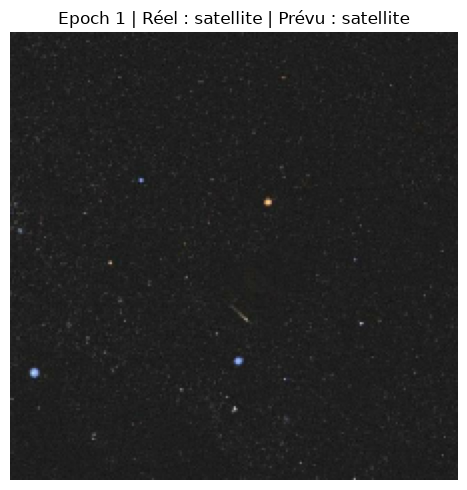

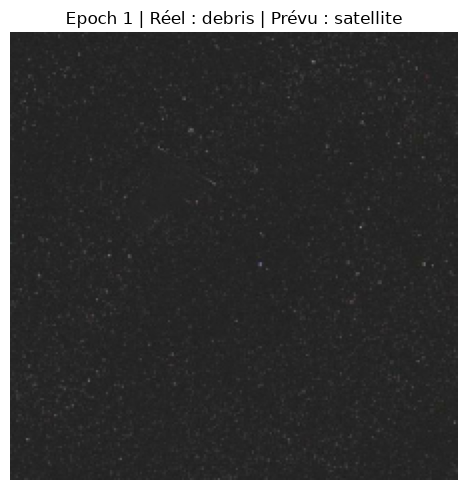

132/132 ━━━━━━━━━━━━━━━━━━━━ 17s 51ms/step - accuracy: 0.9287 - debris_precision: 0.5566 - debris_recall: 0.9516 - loss: 0.2130 - pr_auc: 0.8280 - val_accuracy: 0.9121 - val_debris_precision: 0.0000e+00 - val_debris_recall: 0.0000e+00 - val_loss: 2.8416 - val_pr_auc: 0.0879
Epoch 2/70
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9470 - debris_precision: 0.6325 - debris_recall: 0.9624 - loss: 0.1494 - pr_auc: 0.8793

2026-11-25 09:48:17 [INFO] : root : Epoch 2 - détections validation : satellite=229, debris=10


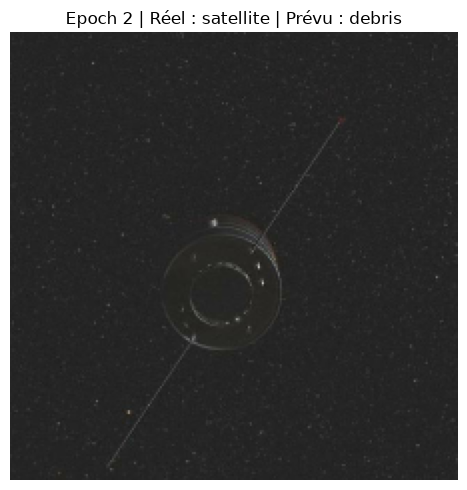

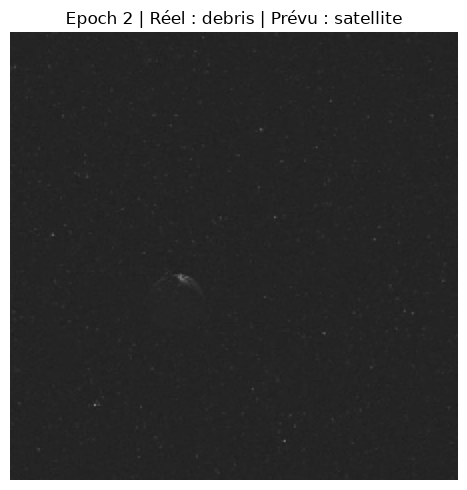

132/132 ━━━━━━━━━━━━━━━━━━━━ 5s 37ms/step - accuracy: 0.9468 - debris_precision: 0.6303 - debris_recall: 0.9624 - loss: 0.1494 - pr_auc: 0.8790 - val_accuracy: 0.8703 - val_debris_precision: 0.0000e+00 - val_debris_recall: 0.0000e+00 - val_loss: 1.1215 - val_pr_auc: 0.0804
Epoch 3/70
131/132 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.9532 - debris_precision: 0.6654 - debris_recall: 0.9516 - loss: 0.1274 - pr_auc: 0.8944

In [ ]:
# BLOQUE 7 - Construction, compilation et entraînement
# MobileNetV2 est fine-tunée, puis compilée avec Adam. Les trois modes de learning
# rate sont testés avec le même pipeline afin de rendre la comparaison reproductible.

import os
from pathlib import Path
from tensorflow import keras

NEXT_MODEL_PATH = Path("src/models/Class_Detection/satellite_debris_hard_70_retrain_v4.keras")
NEXT_MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)

LEARNING_RATE_MODE="hardcoded" 
INITIAL_LEARNING_RATE=1e-3

NB_EPOCHS = 70
# Choix possibles : hardcoded, plateau ou cosine_decay.
# Exemple : LEARNING_RATE_MODE=plateau jupyter notebook Class_detection_training.ipynb
LEARNING_RATE_MODE = os.getenv("LEARNING_RATE_MODE", "cosine_decay").strip().lower()
LEARNING_RATE_MODE = {
    "hardcode": "hardcoded",
    "cosine": "cosine_decay",
}.get(LEARNING_RATE_MODE, LEARNING_RATE_MODE)
INITIAL_LEARNING_RATE = float(os.getenv("INITIAL_LEARNING_RATE", "1e-3"))

if LEARNING_RATE_MODE not in {"cosine_decay", "plateau", "hardcoded"}:
    raise ValueError(
        "LEARNING_RATE_MODE doit être 'hardcoded', 'plateau' ou 'cosine_decay'"
    )
try:
    # Construction et entraînement sur le périphérique choisi dans la configuration globale
    with tf.device(TRAINING_DEVICE):
        base_model = keras.applications.MobileNetV2(
            input_shape=(IMG_SIZE, IMG_SIZE, 3),
            include_top=False,
            weights='imagenet',
        )
        base_model.trainable = True

        # Augmentation aléatoire des deux classes, active uniquement pendant l'entraînement.
        # fill_mode="reflect" évite les coins noirs créés par les rotations.
        data_augmentation = keras.Sequential(
            [
                keras.layers.RandomFlip("horizontal_and_vertical"),
                keras.layers.RandomRotation(0.5, fill_mode="reflect"),
            ],
            name="data_augmentation",
        )

        inputs = keras.Input(shape=(IMG_SIZE, IMG_SIZE, 3))
        x = data_augmentation(inputs)
        x = base_model(x, training=True)
        x = keras.layers.GlobalAveragePooling2D()(x)
        x = keras.layers.Dropout(0.3)(x)
        # Sortie unique : probabilité que l'objet soit un debris
        outputs = keras.layers.Dense(
            1,
            activation="sigmoid",
            name="class_output",
        )(x)
        model = keras.Model(inputs, outputs)

        steps_per_epoch = len(df_train) // BATCH_SIZE
        total_steps = steps_per_epoch * NB_EPOCHS

        if LEARNING_RATE_MODE == "cosine_decay":
            learning_rate = keras.optimizers.schedules.CosineDecay(
                initial_learning_rate=INITIAL_LEARNING_RATE,
                decay_steps=total_steps,
                alpha=1e-2,
            )
        else:
            # Utilisé directement pour le mode hardcoded et comme valeur initiale
            # lorsque ReduceLROnPlateau ajuste le taux pendant l'entraînement.
            learning_rate = INITIAL_LEARNING_RATE

        model.compile(
            optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
            loss=keras.losses.BinaryCrossentropy(),
            metrics=[
                keras.metrics.BinaryAccuracy(name="accuracy"),
                keras.metrics.Recall(name="debris_recall"),
                keras.metrics.Precision(name="debris_precision"),
                keras.metrics.AUC(curve="PR", name="pr_auc"),
            ],
        )


        checkpoint = keras.callbacks.ModelCheckpoint(
            NEXT_MODEL_PATH,
            monitor="val_pr_auc",
            mode="max",
            save_best_only=True,
        )

        early_stopping = keras.callbacks.EarlyStopping(
            monitor="val_pr_auc",
            mode="max",
            patience=65,
            restore_best_weights=True,
        )

        epoch_preview = EpochPreviewCallback(val_classification_ds, CLASS_NAMES)
        callbacks = [checkpoint, early_stopping, epoch_preview, wandb_callback]

        if LEARNING_RATE_MODE == "plateau":
            callbacks.append(
                keras.callbacks.ReduceLROnPlateau(
                    monitor="val_loss",
                    factor=0.5,
                    patience=2,
                    min_lr=1e-6,
                    verbose=1,
                )
            )

        logging.info(
            f"Mode du learning rate : {LEARNING_RATE_MODE} "
            f"(initial={INITIAL_LEARNING_RATE:g})"
        )

        history = model.fit(
            train_classification_ds,
            validation_data=val_classification_ds,
            epochs=NB_EPOCHS,
            class_weight=CLASS_WEIGHT,
            callbacks=callbacks,
        )

    logging.info(f"Modèle ImageNet sauvegardé dans : {NEXT_MODEL_PATH}")
except Exception as e:
    logging.error(f"Erreur pendant l'entraînement : {e}")

## 7. Analyse des résultats

Cette partie distingue les résultats observés sur validation de l'évaluation finale sur test. Les courbes servent à vérifier l'apprentissage et les risques de sur-apprentissage. Elles ne doivent pas être utilisées pour retourner sur le test, modifier le modèle, puis le réévaluer indéfiniment.

### 7.1. Choix du seuil de décision

Une sortie sigmoïde doit être transformée en classe par un seuil. La valeur 0.5 sert de point de départ. Le tableau compare 0.2 à 0.9 sur la validation uniquement :

- un seuil bas augmente le rappel mais peut produire davantage de fausses alertes ;
- un seuil haut réduit les fausses alertes mais peut manquer des debris.

Avec seulement 21 debris dans la validation, un réglage excessivement précis serait instable. Le seuil reste donc simple et est gelé avant le test.


In [ ]:
# BLOQUE 8 - Analyse du seuil sur validation uniquement
# Le seuil est comparé de 0.2 à 0.9 sans toucher au test. Cette table documente
# le compromis recall/fausses alertes avant le gel de DECISION_THRESHOLD.
DECISION_THRESHOLD = 0.5

try:
    y_val = df_val['binary_class_id'].values
    p_val = model.predict(val_classification_ds, verbose=0)[:, 0]

    threshold_table = []
    for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
        predicted_debris = p_val >= threshold
        threshold_table.append({
            'seuil': threshold,
            'débris trouvés': f"{int((predicted_debris & (y_val == 1)).sum())}/{int((y_val == 1).sum())}",
            'fausses alertes': f"{int((predicted_debris & (y_val == 0)).sum())}/{int((y_val == 0).sum())}",
        })

    logging.info(f"Seuil utilisé : {DECISION_THRESHOLD}")
    pd.DataFrame(threshold_table)
except Exception as e:
    logging.error(f"Erreur pendant l'évaluation du seuil : {e}")


## 8. Évaluation finale sur le jeu de test

Cette cellule charge les vraies probabilités du modèle sur les 123 images jamais utilisées pour l'entraînement ou le réglage du seuil. Elle calcule ensuite :

- le rapport précision/rappel/F1 pour les deux classes ;
- l'accuracy globale ;
- la PR-AUC des debris indépendamment du seuil.

Le test ne sert ni à reprendre l'entraînement ni à choisir une nouvelle décision.

In [ ]:
# BLOQUE 9 - Rapport final sur test
# Ce bloc effectue une seule prédiction sur le test, applique le seuil gelé et calcule
# précision, rappel, F1 et PR-AUC. Il ne permet plus de modifier le modèle.
from sklearn.metrics import average_precision_score, classification_report

y_test = df_test['binary_class_id'].values
p_test = model.predict(test_classification_ds, verbose=0)[:, 0]
pred_test = (p_test >= DECISION_THRESHOLD).astype(int)

logging.info(f"Résultats de classification sur le jeu de test (seuil = {DECISION_THRESHOLD:.3f}) :")
logging.info(classification_report(y_test, pred_test, target_names=CLASS_NAMES, digits=4))
logging.info(f"PR-AUC debris (indépendante du seuil) : {average_precision_score(y_test, p_test):.4f}")

## 9. Courbes d’apprentissage

Les courbes suivent côte à côte la perte totale, la PR-AUC des debris et le rappel des debris pour l’entraînement et la validation. Les écarts persistent-ils longtemps entre les deux ensembles ? Une validation en baisse tandis que l’entraînement continue de progresser peut indiquer un sur-apprentissage. Ces graphiques servent de preuve visuelle du processus d’entraînement.


In [ ]:
metrics = history.history

figure, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (metric_name, title) in zip(axes, [
    ("loss", "Loss (pondérée par classe)"),
    ("pr_auc", "PR-AUC debris"),
    ("debris_recall", "Recall debris"),
]):
    axis.plot(history.epoch, metrics[metric_name], "o-", label="train")
    axis.plot(history.epoch, metrics[f"val_{metric_name}"], "o-", label="validation")
    axis.set_title(title)
    axis.set_xlabel("Epoch")
    axis.legend()

plt.tight_layout()
plt.show()

## 10. Matrices de confusion

La matrice de confusion est calculée séparément sur la validation et le test avec le seuil fixé. Elle permet de distinguer les deux types d’erreurs :

- `satellite` prédit comme `debris` : fausse alerte ;
- `debris` prédit comme `satellite` : faux négatif potentiellement important.

Dans le contexte du projet, le rappel des debris reste particulièrement suivi, car manquer un debris doit être évité autant que possible.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


try:
    figure, axes = plt.subplots(1, 2, figsize=(12, 5))

    for axis, (split_name, y_true, probabilities) in zip(axes, [
        ("validation", y_val, p_val),
        ("test", y_test, p_test),
    ]):
        y_pred = (probabilities >= DECISION_THRESHOLD).astype(int)
        cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
        ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES).plot(cmap="Blues", ax=axis, colorbar=False)
        axis.set_title(f"Matrice de confusion - {split_name} (seuil = {DECISION_THRESHOLD:.2f})")
    plt.tight_layout()
    plt.show()
except Exception as e:
    logging.error(f"Erreur lors de l'affichage des matrices de confusion : {e}", exc_info=True)

## 11. Comparaison de toutes les variantes sauvegardées

Cette cellule doit charger uniquement les fichiers `.keras` présents dans `src/models/Class_Detection/` et mesurer la même métrique sur le même test. Elle fournit une comparaison honnête entre les variantes cosinus, hardcoded et plateau.

Le bloc exclut donc les simples copies ou fichiers de sauvegarde temporaires de la comparaison lorsque ces noms ne représentent pas un modèle final identifiable.

In [ ]:
# BLOQUE 13 - Tableau comparatif des variantes finales
# Ce bloc charge les modèles disponibles et les évalue sur test avec des fonctions
# de métriques homogènes, puis trie les résultats pour faciliter la comparaison.
from pathlib import Path

from sklearn.metrics import accuracy_score, average_precision_score, f1_score, precision_score, recall_score

model_paths = sorted(Path("src/models/Class_Detection").glob("*.keras"))
if not model_paths:
    raise FileNotFoundError("Aucun modèle .keras trouvé dans le dossier src/models/Class_Detection.")

y_test_all_models = df_test["binary_class_id"].to_numpy(dtype=int)
comparison_results = []

for model_path in model_paths:
    try:
        candidate_model = keras.models.load_model(model_path, compile=False)
        probabilities = np.asarray(candidate_model.predict(test_classification_ds, verbose=0)).reshape(-1)
        predictions = (probabilities >= DECISION_THRESHOLD).astype(int)
        loss = float(np.mean(keras.losses.binary_crossentropy(y_test_all_models.astype("float32"), probabilities)))
        comparison_results.append({
            "modèle": model_path.name,
            "statut": "OK",
            "loss": loss,
            "accuracy": accuracy_score(y_test_all_models, predictions),
            "precision_debris": precision_score(y_test_all_models, predictions, zero_division=0),
            "recall_debris": recall_score(y_test_all_models, predictions, zero_division=0),
            "f1_debris": f1_score(y_test_all_models, predictions, zero_division=0),
            "pr_auc_debris": average_precision_score(y_test_all_models, probabilities),
        })
    except Exception as error:
        comparison_results.append({"modèle": model_path.name, "statut": f"ERREUR: {type(error).__name__}: {error}"})

classification_comparison = pd.DataFrame(comparison_results)
display(classification_comparison)

## 12. Validation finale du modèle de classification retenu

Cette section est volontairement séparée de la comparaison générale. Elle charge explicitement le candidat retenu provisoirement : `satellite_debris_cosin_70_retrain.keras`.

Elle vérifie le fichier, calcule les probabilités sur le test, applique le seuil gelé à 0.5 et sauvegarde les preuves finales dans `results/final/`. Cette cellule ne sert ni à entraîner ni à modifier le modèle.

In [ ]:
# BLOQUE 14 - Confirmation reproductible du modèle classification retenu
from pathlib import Path
import json
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

FINAL_CLASSIFICATION_MODEL = Path("src/models/Class_Detection/satellite_debris_cosin_70_retrain.keras")
FINAL_RESULTS_DIR = Path("results/final/Classification")
FINAL_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

if not FINAL_CLASSIFICATION_MODEL.exists():
    raise FileNotFoundError(f"Modèle retenu introuvable : {FINAL_CLASSIFICATION_MODEL}")

final_classification_model = keras.models.load_model(FINAL_CLASSIFICATION_MODEL)
y_true = df_test["binary_class_id"].values
probabilities = final_classification_model.predict(test_classification_ds, verbose=0)[:, 0]
y_pred = (probabilities >= DECISION_THRESHOLD).astype(int)

classification_report_text = classification_report(
    y_true,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4,
)
logging.info("Modèle de classification final confirmé : %s", FINAL_CLASSIFICATION_MODEL)
logging.info("\n%s", classification_report_text)

cm = confusion_matrix(y_true, y_pred)
figure, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(cmap="Blues", ax=axis, colorbar=False)
axis.set_title(f"Modèle classification retenu - test (seuil={DECISION_THRESHOLD:.2f})")
figure.tight_layout()
figure.savefig(FINAL_RESULTS_DIR / "classification_confusion_matrix_test.png", dpi=150, bbox_inches="tight")
plt.close(figure)

final_classification_results = {
    "model": str(FINAL_CLASSIFICATION_MODEL),
    "decision_threshold": float(DECISION_THRESHOLD),
    "test_support": len(y_true),
    "test_debris_support": int((y_true == 1).sum()),
    "classification_report": classification_report(
        y_true, y_pred, target_names=CLASS_NAMES, output_dict=True, zero_division=0
    ),
    "confusion_matrix": cm.tolist(),
    "pr_auc_debris": float(average_precision_score(y_true, probabilities)),
}
(FINAL_RESULTS_DIR / "classification_final.json").write_text(
    json.dumps(final_classification_results, indent=2, ensure_ascii=False),
    encoding="utf-8",
)


### 12.1. Courbes finales du candidat retenu

Les courbes doivent provenir de la même exécution qui a produit le fichier `satellite_debris_cosin_70_retrain.keras`. Elles sont exportées dans `results/final/` pour éviter que les courbes affichées ne proviennent d'une ancienne variante ou d'une exécution incomplète.

Si l'objet `history` n'est pas disponible, le notebook indique explicitement qu'il faut relancer l'entraînement du modèle retenu. Il ne produit pas de courbe de substitution.

In [ ]:
# BLOQUE 15 - Courbes finales uniquement si history correspond au candidat retenu
if "history" not in globals():
    logging.warning("Courbes finales non enregistrées : relancer l'entraînement du modèle cosinus retenu pour remplir 'history'.")
else:
    candidate_history = history.history
    metric_specs = [
        ("loss", "Loss"),
        ("pr_auc", "PR-AUC debris"),
        ("debris_recall", "Recall debris"),
    ]
    figure, axes = plt.subplots(1, 3, figsize=(18, 5))
    for axis, (metric_name, title) in zip(axes, metric_specs):
        if metric_name in candidate_history:
            axis.plot(candidate_history[metric_name], label="train")
        if f"val_{metric_name}" in candidate_history:
            axis.plot(candidate_history[f"val_{metric_name}"], label="validation")
        axis.set_title(title)
        axis.set_xlabel("Époque")
        axis.set_ylabel(metric_name)
        axis.grid(alpha=0.3)
        axis.legend()
    figure.tight_layout()
    figure.savefig(FINAL_RESULTS_DIR / "classification_learning_curves.png", dpi=150, bbox_inches="tight")
    plt.close(figure)


### 12.2. Exemples qualitatifs des erreurs de classification

Cette visualisation ne remplace pas les métriques. Elle montre les faux positifs (satellites prédits debris) et les faux négatifs (debris prédits satellites) afin d'analyser les cas réellement difficiles du test.

In [ ]:
# BLOQUE 16 - Faux positifs et faux négatifs classification
import matplotlib.image as mpimg

false_positive_indices = np.flatnonzero((y_true == 0) & (y_pred == 1))
false_negative_indices = np.flatnonzero((y_true == 1) & (y_pred == 0))

logging.info("Faux positifs classification : %d", len(false_positive_indices))
logging.info("Faux négatifs classification : %d", len(false_negative_indices))

if len(false_positive_indices) == 0 and len(false_negative_indices) == 0:
    logging.info("Aucune erreur de classification dans la sortie test analysée.")
else:
    error_indices = list(false_positive_indices[:4]) + list(false_negative_indices[:4])
    if error_indices:
        figure, axes = plt.subplots(1, len(error_indices), figsize=(4 * len(error_indices), 4))
        if len(error_indices) == 1:
            axes = [axes]
        for axis, index in zip(axes, error_indices):
            row = df_test.iloc[index]
            image = mpimg.imread(row["image_path"])
            axis.imshow(image)
            true_name = CLASS_NAMES[int(y_true[index])]
            pred_name = CLASS_NAMES[int(y_pred[index])]
            axis.set_title(f"Réel: {true_name}\nPrédit: {pred_name}\np={probabilities[index]:.3f}")
            axis.axis("off")
        figure.tight_layout()
        figure.savefig(FINAL_RESULTS_DIR / "classification_error_examples.png", dpi=150, bbox_inches="tight")
        plt.close(figure)


### 12.3. Analyse approfondie des erreurs de classification

Cette analyse distingue les erreurs les plus proches du seuil, les faux positifs selon leur confiance et les faux négatifs potentiellement dangereux. Elle permet de voir si une amélioration doit porter sur le seuil, les données difficiles ou les petites caractéristiques visuelles.

In [ ]:
# Analyse quantitative des marges de décision et des objets difficiles
if "probabilities" not in globals() or "y_true" not in globals():
    probabilities = final_model.predict(test_ds, verbose=0)[:, 0]
    y_true = df_test["binary_class_id"].values

y_pred_analysis = (probabilities >= DECISION_THRESHOLD).astype(int)
false_positive_mask = (y_true == 0) & (y_pred_analysis == 1)
false_negative_mask = (y_true == 1) & (y_pred_analysis == 0)

margin_bins = [
    ("Très proche du seuil", np.abs(probabilities - DECISION_THRESHOLD) <= 0.05),
    ("Proche du seuil", (np.abs(probabilities - DECISION_THRESHOLD) > 0.05) & (np.abs(probabilities - DECISION_THRESHOLD) <= 0.15)),
    ("Confiant", np.abs(probabilities - DECISION_THRESHOLD) > 0.15),
]
margin_rows = []
for label, mask in margin_bins:
    total = int(mask.sum())
    errors = int((mask & (y_pred_analysis != y_true)).sum())
    margin_rows.append({
        "catégorie_confiance": label,
        "nombre": total,
        "erreurs": errors,
        "taux_erreur_%": round(100 * errors / total, 2) if total else 0.0,
    })
margin_table = pd.DataFrame(margin_rows)

error_rows = []
for index in np.flatnonzero(false_positive_mask):
    error_rows.append({"type": "faux positif", "indice_test": int(index), "probabilité_debris": float(probabilities[index]), "image": str(df_test.iloc[index]["image_path"])})
for index in np.flatnonzero(false_negative_mask):
    error_rows.append({"type": "faux négatif", "indice_test": int(index), "probabilité_debris": float(probabilities[index]), "image": str(df_test.iloc[index]["image_path"])})
error_table = pd.DataFrame(error_rows)

logging.info("Analyse par confiance :\n%s", margin_table.to_string(index=False))
logging.info("Erreurs ordonnées par confiance :\n%s", error_table.sort_values("probabilité_debris", ascending=False).to_string(index=False))
margin_table.to_csv(FINAL_RESULTS_DIR / "classification_confidence_analysis.csv", index=False)
error_table.to_csv(FINAL_RESULTS_DIR / "classification_error_cases.csv", index=False)

figure, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].hist(probabilities[y_true == 0], bins=20, range=(0, 1), alpha=0.65, label="réel satellite")
axes[0].hist(probabilities[y_true == 1], bins=20, range=(0, 1), alpha=0.65, label="réel debris")
axes[0].axvline(DECISION_THRESHOLD, color="black", linestyle="--", label="seuil")
axes[0].set(title="Distribution des probabilités - test", xlabel="Probabilité debris", ylabel="Nombre")
axes[0].legend()

margin_table.plot(x="catégorie_confiance", y="taux_erreur_%", kind="bar", ax=axes[1], legend=False)
axes[1].set(title="Taux d'erreur selon la marge au seuil", xlabel="", ylabel="Taux d'erreur (%)")
axes[1].tick_params(axis="x", rotation=20)
figure.tight_layout()
figure.savefig(FINAL_RESULTS_DIR / "classification_error_analysis.png", dpi=150, bbox_inches="tight")
plt.close(figure)
